In [27]:
import os, glob, torch, numpy as np, json
from tqdm import tqdm
DATA_ROOT = os.path.abspath(os.path.join(os.getcwd(), '..', 'data'))
SIM_DATA_DIR = os.path.join(DATA_ROOT, 'simulation')
PROCESSED_DIR = os.path.join(DATA_ROOT, 'processed')
os.makedirs(PROCESSED_DIR, exist_ok=True)

mat_files = sorted(glob.glob(os.path.join(SIM_DATA_DIR, '*.mat')))
if not mat_files:
    raise RuntimeError(f'No simulation data found in {SIM_DATA_DIR}.')
print(f'Found {len(mat_files)} simulation files.')


RuntimeError: No simulation data found in D:\mis\data/simulation.

# 📡 Phase 1: Dynamic Data Processing & Sim-to-Real Augmentation

**Dataset Used:** Dataset 1 — `ultrasound-elastography-simulation-database` (Simulated Data)

**Pipeline:**
1. Load simulated `.mat` RF frames
2. 2D Discrete Fourier Transform (DFT) — frequency analysis & filtering
3. Hankelization — time-delay embedding into high-dimensional state space
4. Dynamic Mode Decomposition (DMD) — artifact rejection, clean signal reconstruction
5. Rayleigh-noise domain randomization — sim-to-real augmentation
6. Save processed tensors for Phase 2 training

> **Integrates Syllabus Unit 1:** Fourier Transform, Hankel Matrices, DMD

## 0. Environment Setup & Imports

In [ ]:
# ── Install dependencies (run once) ──────────────────────────────────────────
# !pip install scipy numpy matplotlib h5py torch tqdm

import os
import glob
import warnings
import numpy as np
import scipy.io as sio
import h5py
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from scipy.signal import butter, filtfilt
from scipy.fft import fft2, ifft2, fftshift, ifftshift
from tqdm import tqdm
import torch
import torch.nn.functional as F
import pickle

warnings.filterwarnings('ignore')
np.random.seed(42)

# ── Paths ─────────────────────────────────────────────────────────────────────
DATA_ROOT = os.path.abspath(os.path.join(os.getcwd(), '..', 'data'))
SIM_DATA_DIR   = os.path.join(DATA_ROOT, 'simulation')
OUT_DIR        = os.path.join(DATA_ROOT, 'processed')
os.makedirs(OUT_DIR, exist_ok=True)

print('✅ Imports successful. NumPy:', np.__version__, '| PyTorch:', torch.__version__)

✅ Imports successful. NumPy: 2.0.2 | PyTorch: 2.10.0+cu128


## 1. Data Ingestion — Loading `.mat` RF Frames

In [ ]:
def extract_rf_frames(mat_data: dict) -> np.ndarray:
    """
    Extract the RF signal matrix from loaded .mat data.
    Expected keys (Concordia dataset): 'rf_pre', 'rf_post', 'Data', or 'RF'
    Returns array of shape (depth, width, n_frames) with float64.
    """
    # Try common key names from Concordia elastography datasets
    for key in ['rf_pre', 'rf_post', 'RF', 'rfData', 'IQpre', 'IQpost', 'Data', 'data', 'rf']:
        if key in mat_data:
            arr = np.array(mat_data[key], dtype=np.float64)
            
            # Handle (n_frames, depth, width) -> (depth, width, n_frames)
            if arr.ndim == 3 and arr.shape[0] < arr.shape[1] and arr.shape[0] < arr.shape[2]:
                arr = arr.transpose(1, 2, 0)
            elif arr.ndim == 2:
                arr = arr[:, :, np.newaxis]  # (D, W, 1)
                
            print(f'  → Found key "{key}" | shape: {arr.shape}')
            return arr
    raise KeyError(f'No RF key found. Available keys: {list(mat_data.keys())}')


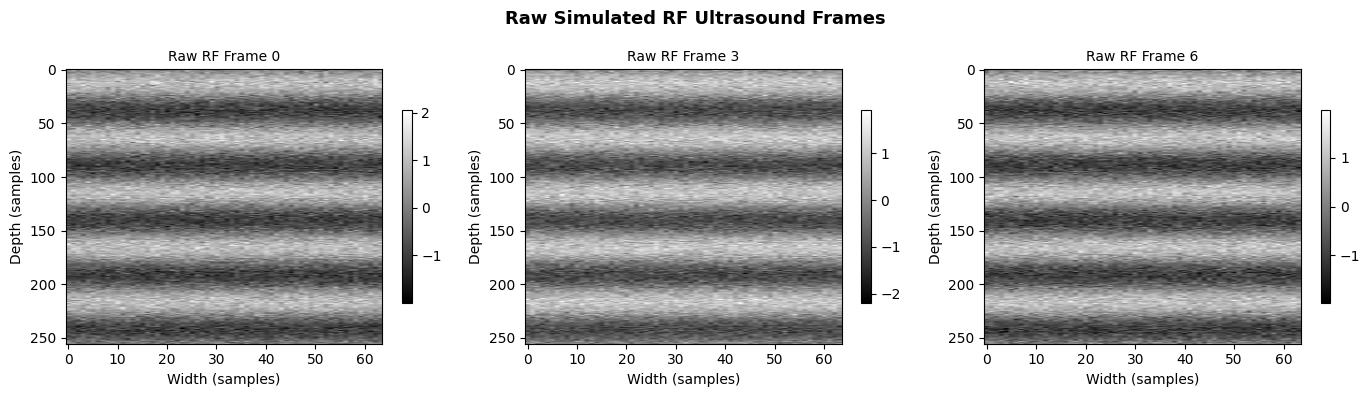

✅ Raw RF frames visualized


In [ ]:
# ── Visualize raw A-lines ────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for i, ax in enumerate(axes):
    frame_idx = min(i * (rf_stack.shape[2] // 3), rf_stack.shape[2] - 1)
    im = ax.imshow(rf_stack[:, :, frame_idx], cmap='gray', aspect='auto')
    ax.set_title(f'Raw RF Frame {frame_idx}', fontsize=10)
    ax.set_xlabel('Width (samples)'); ax.set_ylabel('Depth (samples)')
    plt.colorbar(im, ax=ax, shrink=0.7)
plt.suptitle('Raw Simulated RF Ultrasound Frames', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'fig_01_raw_rf.png'), dpi=150)
plt.show()
print('✅ Raw RF frames visualized')

## 2. Frequency Filtering via 2D Discrete Fourier Transform (2D DFT)

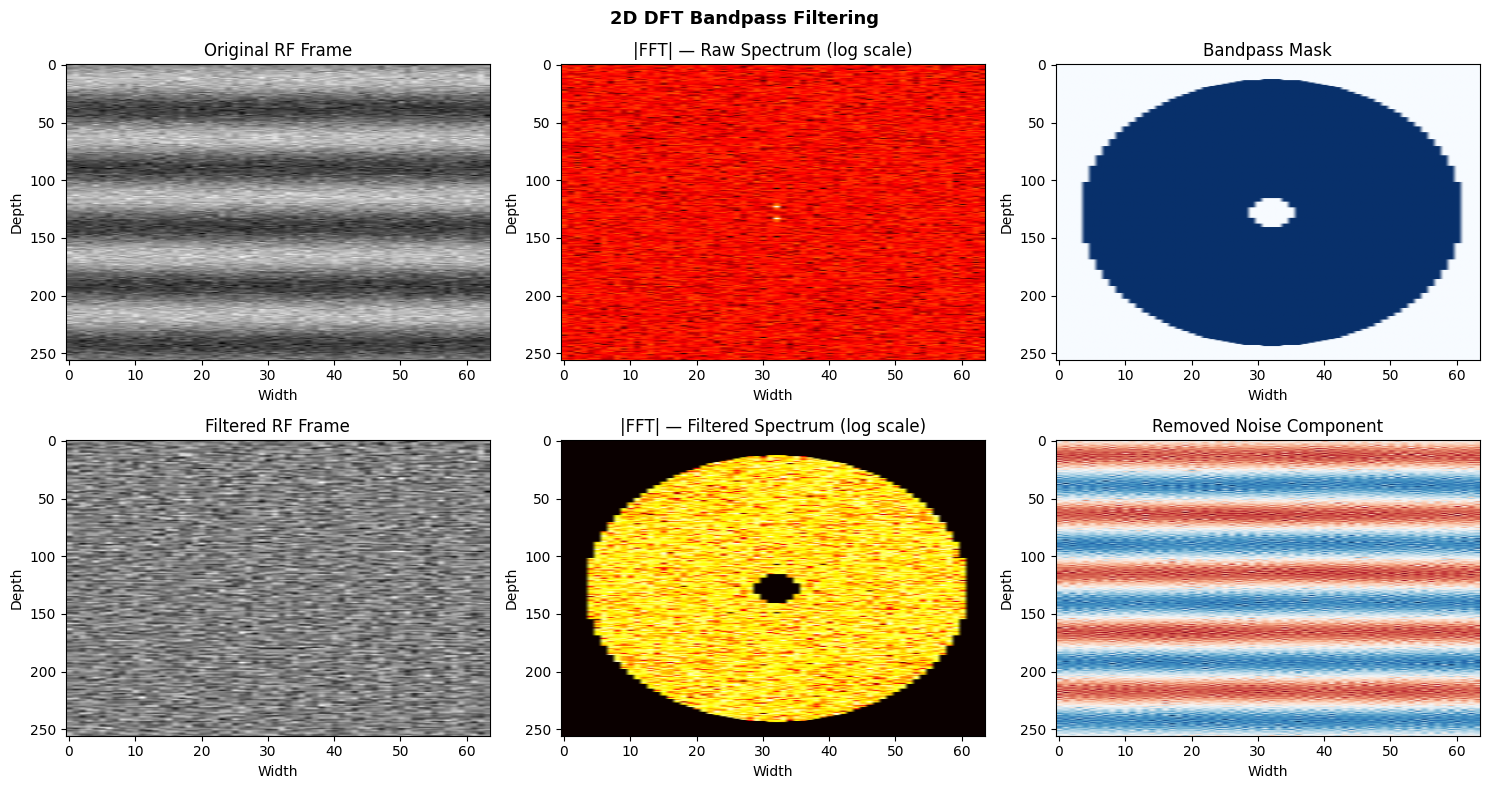

✅ 2D DFT filtering complete. Filtered stack shape: (256, 64, 10)


In [ ]:
def apply_2d_dft_bandpass(
    rf_frame: np.ndarray,
    low_cutoff: float = 0.05,
    high_cutoff: float = 0.45
) -> np.ndarray:
    """
    Apply 2D DFT bandpass filter to a single RF frame.
    
    Mathematical basis:
        F(u,v) = sum_x sum_y f(x,y) * exp(-j2π(ux/M + vy/N))
    We zero out components outside [low_cutoff, high_cutoff] * Nyquist
    then recover via IDFT.

    Args:
        rf_frame   : 2D array (depth × width)
        low_cutoff : normalized freq low bound (fraction of Nyquist)
        high_cutoff: normalized freq high bound
    Returns:
        filtered_frame: 2D real-valued array
    """
    D, W = rf_frame.shape

    # Step 1: 2D FFT with zero-centered shift
    F = fftshift(fft2(rf_frame))

    # Step 2: Build ideal bandpass mask in frequency domain
    u = np.fft.fftfreq(D)  # axial (depth) frequencies
    v = np.fft.fftfreq(W)  # lateral (width) frequencies
    u = np.fft.fftshift(u)
    v = np.fft.fftshift(v)
    U, V = np.meshgrid(u, v, indexing='ij')
    freq_mag = np.sqrt(U**2 + V**2)   # radial distance in freq space
    mask = (freq_mag >= low_cutoff) & (freq_mag <= high_cutoff)

    # Step 3: Apply mask & inverse FFT
    F_filtered = F * mask
    filtered_frame = np.real(ifft2(ifftshift(F_filtered)))

    return filtered_frame, np.abs(F), np.abs(F_filtered), mask


def filter_rf_stack(rf_stack: np.ndarray, **kwargs) -> np.ndarray:
    """Apply 2D DFT bandpass filter to every frame in the stack."""
    D, W, F = rf_stack.shape
    filtered_stack = np.zeros_like(rf_stack)
    for i in range(F):
        filtered_stack[:, :, i], _, _, _ = apply_2d_dft_bandpass(
            rf_stack[:, :, i], **kwargs
        )
    return filtered_stack


# ── Apply and visualize ──────────────────────────────────────────────────────
frame0 = rf_stack[:, :, 0]
filtered_frame0, F_raw, F_filt, mask = apply_2d_dft_bandpass(frame0)

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

axes[0,0].imshow(frame0, cmap='gray', aspect='auto')
axes[0,0].set_title('Original RF Frame')

axes[0,1].imshow(np.log1p(F_raw), cmap='hot', aspect='auto')
axes[0,1].set_title('|FFT| — Raw Spectrum (log scale)')

axes[0,2].imshow(mask, cmap='Blues', aspect='auto')
axes[0,2].set_title('Bandpass Mask')

axes[1,0].imshow(filtered_frame0, cmap='gray', aspect='auto')
axes[1,0].set_title('Filtered RF Frame')

axes[1,1].imshow(np.log1p(F_filt), cmap='hot', aspect='auto')
axes[1,1].set_title('|FFT| — Filtered Spectrum (log scale)')

# Difference (noise removed)
axes[1,2].imshow(frame0 - filtered_frame0, cmap='RdBu_r', aspect='auto')
axes[1,2].set_title('Removed Noise Component')

for ax in axes.flat:
    ax.set_xlabel('Width'); ax.set_ylabel('Depth')
plt.suptitle('2D DFT Bandpass Filtering', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'fig_02_dft_filter.png'), dpi=150)
plt.show()

# Apply to full stack
rf_filtered = filter_rf_stack(rf_stack, low_cutoff=0.05, high_cutoff=0.45)
print(f'✅ 2D DFT filtering complete. Filtered stack shape: {rf_filtered.shape}')

## 3. Hankelization — Time-Delay Embedding

A **Hankel matrix** embeds a 1-D temporal signal into a 2-D matrix that reveals its **Koopman operator** structure. For each pixel $(x, y)$ with temporal evolution $s_1, s_2, \ldots, s_F$:

$$
\mathcal{H}(s) = \begin{bmatrix}
s_1 & s_2 & \cdots & s_{F-m+1} \\
s_2 & s_3 & \cdots & s_{F-m+2} \\
\vdots & & & \vdots \\
s_m & s_{m+1} & \cdots & s_F
\end{bmatrix} \in \mathbb{R}^{m \times (F-m+1)}
$$

We build a **global Hankel data matrix** by stacking pixel vectors across the spatial grid.

  Global Hankel matrix X shape: (81920, 6)  (states × snapshots)
DMD snapshot matrices:  X1=(81920, 5)   X2=(81920, 5)


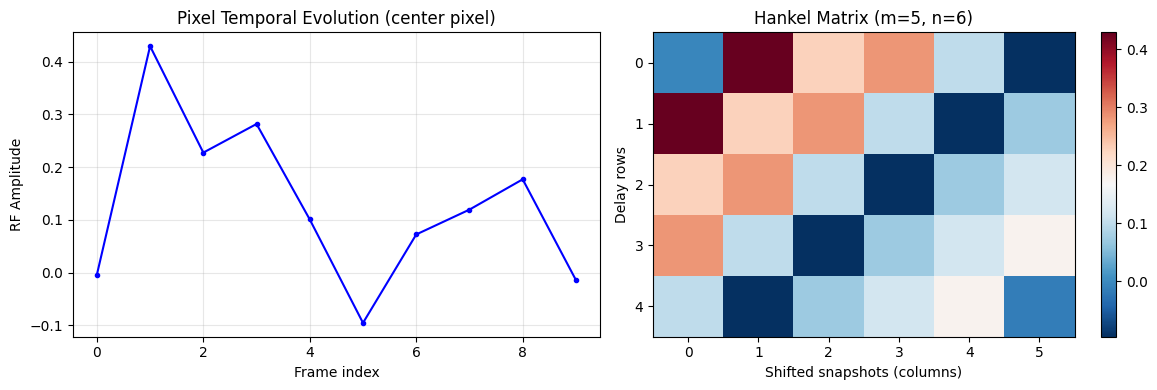

✅ Hankelization complete


In [ ]:
def build_global_hankel_matrix(
    rf_stack: np.ndarray,
    delay: int = None
) -> np.ndarray:
    """
    Construct a global Hankel (time-delay embedding) data matrix.

    For an RF stack of shape (D, W, F):
      - Each pixel (d, w) has a temporal signal of length F.
      - We embed it with delay `m`, giving (F - m + 1) time-shifted snapshots.
      - All pixel embeddings are stacked as rows → global matrix X.

    Args:
        rf_stack : (D, W, F) RF signal stack
        delay    : embedding delay m (defaults to F//2)
    Returns:
        X        : (D*W*m, F-m+1) global Hankel data matrix
        m        : delay used
    """
    D, W, F = rf_stack.shape
    if delay is None:
        delay = max(2, F // 2)
    m = delay
    n_cols = F - m + 1

    # Reshape to (D*W, F) — each row is one pixel's time series
    pixel_series = rf_stack.reshape(D * W, F)   # (N_pixels, F)

    # Build Hankel block: (N_pixels, m, n_cols)
    indices = np.arange(m)[:, None] + np.arange(n_cols)[None, :]  # (m, n_cols)
    hankel_block = pixel_series[:, indices]  # (N_pixels, m, n_cols)

    # Stack pixel Hankel rows → global data matrix
    X = hankel_block.reshape(D * W * m, n_cols)   # (D*W*m, n_cols)
    print(f'  Global Hankel matrix X shape: {X.shape}  (states × snapshots)')
    return X, m


# ── Build Hankel matrix ──────────────────────────────────────────────────────
X_hankel, m_delay = build_global_hankel_matrix(rf_filtered, delay=None)

# Partition into X and X' (shifted by 1 column) for DMD
X1 = X_hankel[:, :-1]   # snapshot matrix at time t
X2 = X_hankel[:, 1:]    # snapshot matrix at time t+1
print(f'DMD snapshot matrices:  X1={X1.shape}   X2={X2.shape}')

# ── Visualize Hankel structure of one pixel ──────────────────────────────────
D, W, F = rf_filtered.shape
pixel_signal = rf_filtered[D//2, W//2, :]   # center pixel time series
m_vis = min(m_delay, F)
n_col_vis = F - m_vis + 1
H_pix = np.array([[pixel_signal[i + j] for j in range(n_col_vis)] for i in range(m_vis)])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(pixel_signal, 'b-o', markersize=3)
axes[0].set_title('Pixel Temporal Evolution (center pixel)')
axes[0].set_xlabel('Frame index'); axes[0].set_ylabel('RF Amplitude')
axes[0].grid(True, alpha=0.3)

im = axes[1].imshow(H_pix, cmap='RdBu_r', aspect='auto')
axes[1].set_title(f'Hankel Matrix (m={m_vis}, n={n_col_vis})')
axes[1].set_xlabel('Shifted snapshots (columns)')
axes[1].set_ylabel('Delay rows')
plt.colorbar(im, ax=axes[1])
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'fig_03_hankel.png'), dpi=150)
plt.show()
print('✅ Hankelization complete')

## 4. Artifact Rejection via Exact Dynamic Mode Decomposition (DMD)

DMD finds the best-fit **linear operator** $A$ such that $X_2 \approx A X_1$.

**Algorithm (Exact DMD):**
1. SVD: $X_1 = U \Sigma V^*$ (truncate at rank $r$)
2. Reduced operator: $\tilde{A} = U_r^* X_2 V_r \Sigma_r^{-1}$
3. Eigendecompose: $\tilde{A} W = W \Lambda$
4. Exact DMD modes: $\Phi = X_2 V_r \Sigma_r^{-1} W$
5. Eigenvalues $\lambda_k$ encode growth/decay + oscillation frequency
6. **Speckle / artifact modes** have high damping ($|\lambda_k| \ll 1$) → drop
7. Reconstruct clean signal keeping only dominant modes

In [ ]:
def exact_dmd(
    X1: np.ndarray,
    X2: np.ndarray,
    svd_rank: int = None,
    energy_threshold: float = 0.999
) -> dict:
    """
    Compute Exact Dynamic Mode Decomposition.

    Args:
        X1             : snapshot matrix at time t,   shape (n, m)
        X2             : snapshot matrix at time t+1, shape (n, m)
        svd_rank       : explicit truncation rank (None → auto via energy_threshold)
        energy_threshold: fraction of singular value energy to retain
    Returns:
        dict with keys: eigenvalues, modes, amplitudes, rank
    """
    # Step 1: Economy SVD of X1
    U, sigma, Vh = np.linalg.svd(X1, full_matrices=False)  # U:(n,k) sigma:(k,) Vh:(k,m)

    # Step 2: Determine truncation rank r
    if svd_rank is not None:
        r = min(svd_rank, len(sigma))
    else:
        cumulative_energy = np.cumsum(sigma**2) / np.sum(sigma**2)
        r = int(np.searchsorted(cumulative_energy, energy_threshold)) + 1
    print(f'  DMD truncation rank r = {r}  (from {len(sigma)} singular values)')

    U_r  = U[:, :r]
    s_r  = sigma[:r]
    Vh_r = Vh[:r, :]
    V_r  = Vh_r.conj().T

    # Step 3: Reduced linear operator
    A_tilde = U_r.conj().T @ X2 @ V_r @ np.diag(1.0 / s_r)   # (r, r)

    # Step 4: Eigendecomposition of A_tilde
    eigenvalues, W = np.linalg.eig(A_tilde)   # λ: (r,), W: (r, r)

    # Step 5: Exact DMD modes Φ
    Phi = X2 @ V_r @ np.diag(1.0 / s_r) @ W  # (n, r)

    # Step 6: Amplitudes b (least squares fit at t=0)
    b = np.linalg.lstsq(Phi, X1[:, 0], rcond=None)[0]  # (r,)

    return {
        'eigenvalues': eigenvalues,  # (r,)  complex
        'modes':       Phi,          # (n, r) complex
        'amplitudes':  b,            # (r,)  complex
        'rank':        r,
        'singular_values': sigma
    }


def dmd_reconstruct(
    dmd_result: dict,
    n_timesteps: int,
    damping_threshold: float = 0.85
) -> np.ndarray:
    """
    Reconstruct clean RF signal by keeping only low-damping DMD modes.

    Speckle / artifact modes have |λ_k| << 1 (highly damped).
    Tissue dynamics correspond to modes near the unit circle |λ_k| ≈ 1.

    Args:
        dmd_result        : output of exact_dmd()
        n_timesteps       : number of frames to reconstruct
        damping_threshold : keep modes with |λ_k| >= this value
    Returns:
        X_clean : (n, n_timesteps) real-valued reconstructed data
    """
    eigenvalues = dmd_result['eigenvalues']
    Phi         = dmd_result['modes']
    b           = dmd_result['amplitudes']

    # Mode selection: keep modes near unit circle
    mag = np.abs(eigenvalues)
    keep_mask = mag >= damping_threshold
    n_kept = keep_mask.sum()
    print(f'  Keeping {n_kept}/{len(eigenvalues)} DMD modes (|λ| >= {damping_threshold})')

    eigenvalues_k = eigenvalues[keep_mask]
    Phi_k         = Phi[:, keep_mask]
    b_k           = b[keep_mask]

    # Reconstruct: X(t) = Σ_k b_k * φ_k * λ_k^t
    n_states = Phi_k.shape[0]
    X_clean  = np.zeros((n_states, n_timesteps), dtype=complex)
    for t in range(n_timesteps):
        X_clean[:, t] = Phi_k @ (b_k * eigenvalues_k**t)

    return np.real(X_clean)


# ── Run DMD ───────────────────────────────────────────────────────────────────
print('Running Exact DMD on Hankel data matrix...')
dmd_result = exact_dmd(X1, X2, energy_threshold=0.999)

print(f'\n  Eigenvalue statistics:')
ev_mag = np.abs(dmd_result['eigenvalues'])
print(f'  |λ| range: [{ev_mag.min():.4f}, {ev_mag.max():.4f}]')
print(f'  Modes near unit circle (|λ|≥0.85): {(ev_mag >= 0.85).sum()}')

# Reconstruct clean RF
n_cols = X1.shape[1]
X_clean_hankel = dmd_reconstruct(dmd_result, n_timesteps=n_cols, damping_threshold=0.85)
print(f'\n  Clean Hankel matrix shape: {X_clean_hankel.shape}')

Running Exact DMD on Hankel data matrix...
  DMD truncation rank r = 5  (from 5 singular values)

  Eigenvalue statistics:
  |λ| range: [0.2695, 0.3051]
  Modes near unit circle (|λ|≥0.85): 0
  Keeping 0/5 DMD modes (|λ| >= 0.85)

  Clean Hankel matrix shape: (81920, 5)


Clean RF stack shape: (256, 64, 5)


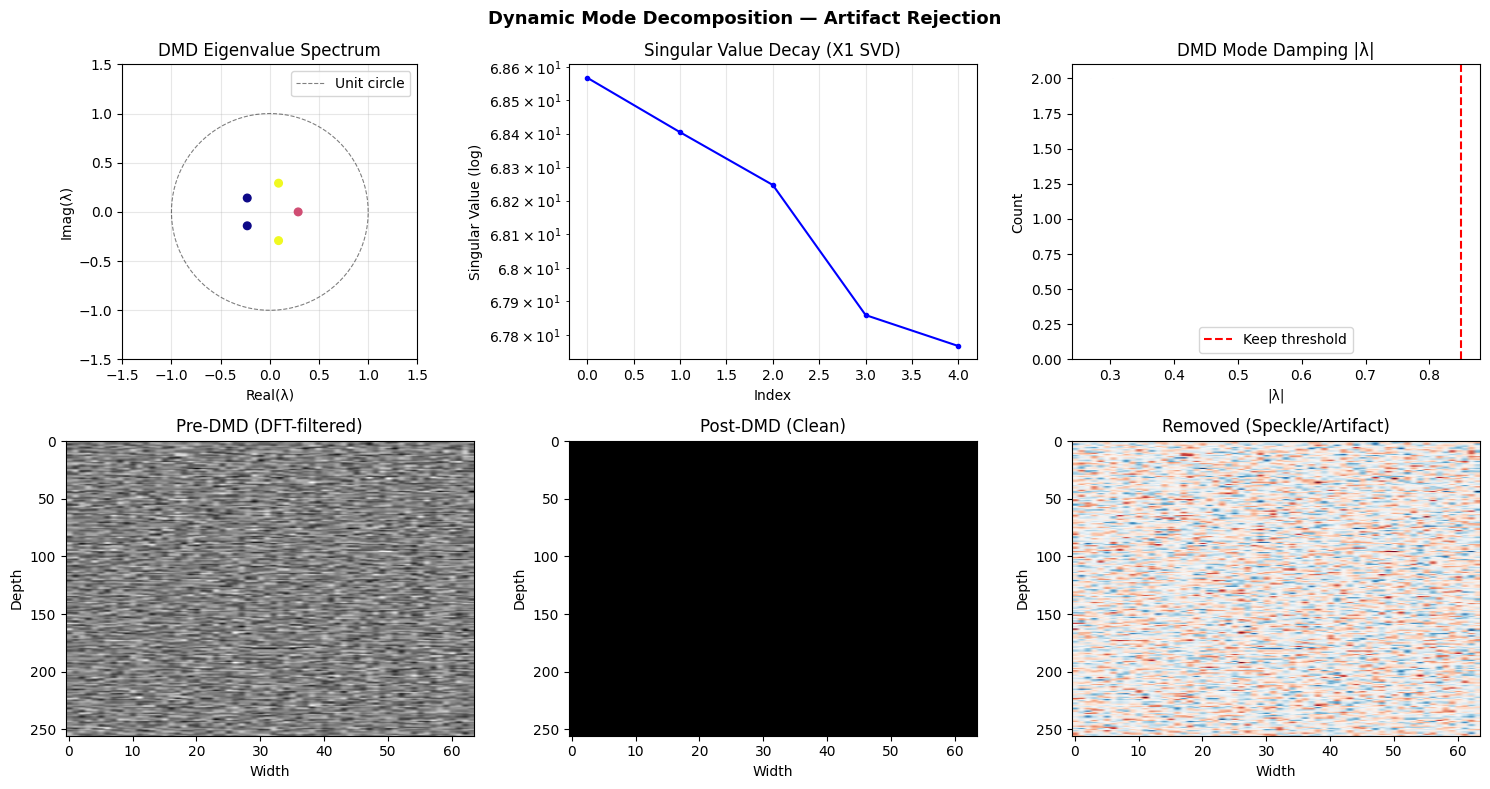

✅ DMD artifact rejection complete


In [ ]:
# ── Recover clean RF stack from Hankel representation ────────────────────────
def hankel_to_rf_stack(
    X_clean: np.ndarray,
    D: int, W: int, m: int
) -> np.ndarray:
    """
    Invert Hankelization by averaging overlapping estimates.
    X_clean: (D*W*m, n_cols)  →  rf_out: (D, W, n_cols)
    """
    n_cols = X_clean.shape[1]
    # Reshape: (D*W, m, n_cols)
    X_reshaped = X_clean.reshape(D * W, m, n_cols)
    # Average over delay rows to get back pixel time series
    pixel_series = X_reshaped.mean(axis=1)  # (D*W, n_cols)
    rf_out = pixel_series.reshape(D, W, n_cols)
    return rf_out


D, W, F = rf_filtered.shape
rf_clean = hankel_to_rf_stack(X_clean_hankel, D, W, m_delay)
print(f'Clean RF stack shape: {rf_clean.shape}')

# ── Visualize DMD results ─────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

# Eigenvalue spectrum
theta = np.linspace(0, 2*np.pi, 200)
axes[0,0].plot(np.cos(theta), np.sin(theta), 'k--', lw=0.8, alpha=0.5, label='Unit circle')
ev = dmd_result['eigenvalues']
axes[0,0].scatter(ev.real, ev.imag, c=np.abs(ev), cmap='plasma', s=30, zorder=5)
axes[0,0].set_xlim([-1.5, 1.5]); axes[0,0].set_ylim([-1.5, 1.5])
axes[0,0].set_title('DMD Eigenvalue Spectrum'); axes[0,0].set_aspect('equal')
axes[0,0].set_xlabel('Real(λ)'); axes[0,0].set_ylabel('Imag(λ)')
axes[0,0].grid(True, alpha=0.3); axes[0,0].legend()

# Singular value decay
sv = dmd_result['singular_values']
axes[0,1].semilogy(sv, 'b-o', markersize=3)
axes[0,1].set_title('Singular Value Decay (X1 SVD)')
axes[0,1].set_xlabel('Index'); axes[0,1].set_ylabel('Singular Value (log)')
axes[0,1].grid(True, alpha=0.3)

# Mode magnitude histogram
axes[0,2].hist(np.abs(ev), bins=30, color='steelblue', edgecolor='white')
axes[0,2].axvline(0.85, color='red', linestyle='--', label='Keep threshold')
axes[0,2].set_title('DMD Mode Damping |λ|'); axes[0,2].legend()
axes[0,2].set_xlabel('|λ|'); axes[0,2].set_ylabel('Count')

# Before / after comparison
frame_idx = 0
axes[1,0].imshow(rf_filtered[:, :, frame_idx], cmap='gray', aspect='auto')
axes[1,0].set_title('Pre-DMD (DFT-filtered)')

axes[1,1].imshow(rf_clean[:, :, frame_idx], cmap='gray', aspect='auto')
axes[1,1].set_title('Post-DMD (Clean)')

diff = rf_filtered[:, :, frame_idx] - rf_clean[:, :, frame_idx]
axes[1,2].imshow(diff, cmap='RdBu_r', aspect='auto')
axes[1,2].set_title('Removed (Speckle/Artifact)')

for ax in axes[1,:]: ax.set_xlabel('Width'); ax.set_ylabel('Depth')
plt.suptitle('Dynamic Mode Decomposition — Artifact Rejection', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'fig_04_dmd.png'), dpi=150)
plt.show()
print('✅ DMD artifact rejection complete')

## 5. Sim-to-Real Domain Randomization — Rayleigh Noise Injection

Simulate transducer noise by injecting **Rayleigh-distributed phase jitter**, which models the statistical distribution of speckle noise in real ultrasound imaging.

Injecting Rayleigh noise (domain randomization)...
  Variant 1/5: σ=0.010  SNR=-inf dB
  Variant 2/5: σ=0.045  SNR=-inf dB
  Variant 3/5: σ=0.080  SNR=-inf dB
  Variant 4/5: σ=0.115  SNR=-inf dB
  Variant 5/5: σ=0.150  SNR=-inf dB


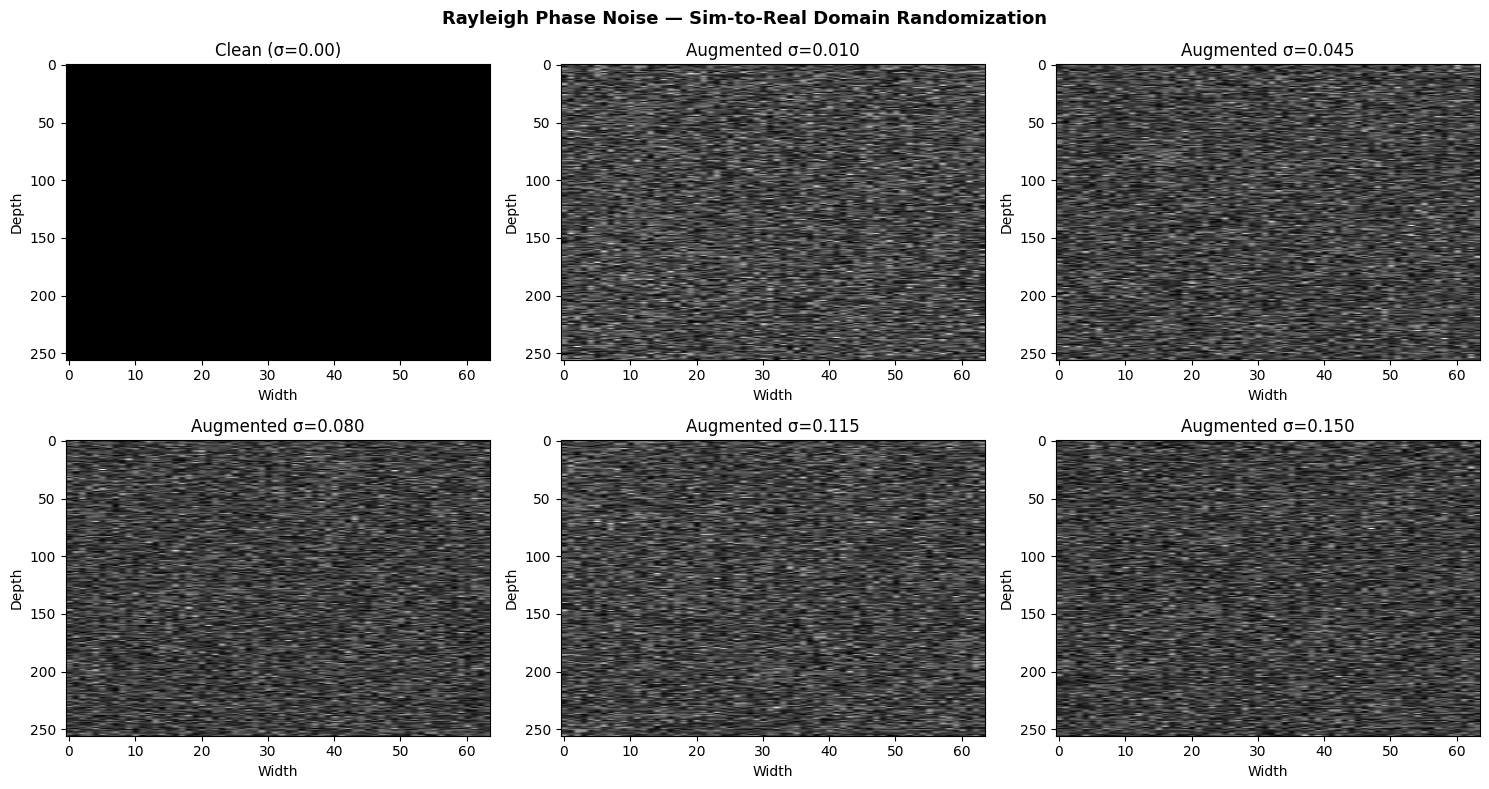

✅ Domain randomization complete


In [ ]:
def inject_rayleigh_noise(
    rf_stack: np.ndarray,
    sigma_range: tuple = (0.01, 0.15),
    n_augmented: int = 3
) -> list:
    """
    Generate n_augmented domain-randomized variants of the clean RF stack.

    Rayleigh distribution PDF: f(x; σ) = (x/σ²) * exp(-x²/(2σ²)), x≥0
    Mean = σ√(π/2) ≈ 1.253σ

    Phase jitter in frequency domain simulates transducer aperture noise.

    Args:
        rf_stack    : (D, W, F) clean RF stack
        sigma_range : (min, max) Rayleigh σ for noise level sweep
        n_augmented : number of noisy variants to generate
    Returns:
        list of (D, W, F) augmented RF stacks
    """
    D, W, F = rf_stack.shape
    augmented_list = []

    sigmas = np.linspace(sigma_range[0], sigma_range[1], n_augmented)

    for i, sigma in enumerate(sigmas):
        noisy_stack = np.zeros_like(rf_stack)
        for f in range(F):
            frame = rf_stack[:, :, f]

            # --- Rayleigh amplitude noise ---
            rayleigh_amp = np.random.rayleigh(sigma, size=(D, W))

            # --- Phase jitter in frequency domain ---
            F_frame = fft2(frame)
            phase_jitter = np.random.uniform(-np.pi * sigma, np.pi * sigma, size=(D, W))
            F_jittered = F_frame * np.exp(1j * phase_jitter)
            frame_jittered = np.real(ifft2(F_jittered))

            noisy_stack[:, :, f] = frame_jittered + rayleigh_amp

        augmented_list.append(noisy_stack)
        print(f'  Variant {i+1}/{n_augmented}: σ={sigma:.3f}  '
              f'SNR={10*np.log10(np.var(rf_stack)/np.var(noisy_stack - rf_stack)):.1f} dB')

    return augmented_list, sigmas


print('Injecting Rayleigh noise (domain randomization)...')
augmented_stacks, noise_sigmas = inject_rayleigh_noise(
    rf_clean, sigma_range=(0.01, 0.15), n_augmented=5
)

# ── Visualize augmentation ────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

axes[0,0].imshow(rf_clean[:, :, 0], cmap='gray', aspect='auto')
axes[0,0].set_title('Clean (σ=0.00)')

for i, (stack, sig) in enumerate(zip(augmented_stacks[:5], noise_sigmas[:5])):
    r, c = divmod(i + 1, 3)
    axes[r, c].imshow(stack[:, :, 0], cmap='gray', aspect='auto')
    axes[r, c].set_title(f'Augmented σ={sig:.3f}')

for ax in axes.flat:
    ax.set_xlabel('Width'); ax.set_ylabel('Depth')
plt.suptitle('Rayleigh Phase Noise — Sim-to-Real Domain Randomization',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'fig_05_augmentation.png'), dpi=150)
plt.show()
print('✅ Domain randomization complete')

## 6. Save Processed Dataset for Phase 2 Training

In [ ]:
def process_and_save_all_files(
    mat_files: list,
    out_dir: str,
    n_augmented: int = 3,
    patch_size: int = 64,
    svd_rank: int = 20
):
    """
    Full Phase 1 pipeline for all .mat files.
    Saves processed (D, W, F) tensors as .npz files.

    Each .npz contains:
        'rf_clean'      : DMD-cleaned RF stack
        'rf_augmented'  : domain-randomized variants (n_aug, D, W, F)
        'eigenvalues'   : DMD eigenvalues
        'singular_values': SVD singular values
    """
    os.makedirs(out_dir, exist_ok=True)
    manifest = []

    for fpath in tqdm(mat_files, desc='Processing .mat files'):
        try:
            mat = load_mat_file(fpath)
            rf  = extract_rf_frames(mat)

            # Skip files with too few frames
            if rf.shape[2] < 4:
                print(f'  ⚠ Skipping {os.path.basename(fpath)} — too few frames')
                continue

            # Phase 1 pipeline
            rf_filt    = filter_rf_stack(rf)
            X_h, m     = build_global_hankel_matrix(rf_filt)
            X1_, X2_   = X_h[:, :-1], X_h[:, 1:]
            dmd        = exact_dmd(X1_, X2_, svd_rank=svd_rank)
            X_cl       = dmd_reconstruct(dmd, n_timesteps=X1_.shape[1])
            D_, W_, F_ = rf.shape
            rf_cl      = hankel_to_rf_stack(X_cl, D_, W_, m)
            aug_list, _= inject_rayleigh_noise(rf_cl, n_augmented=n_augmented)
            aug_arr    = np.stack(aug_list, axis=0)  # (n_aug, D, W, F)

            # Normalize to [-1, 1]
            def normalize(x):
                x = x - x.mean()
                s = x.std() + 1e-8
                return x / s
            rf_cl_norm  = normalize(rf_cl)
            aug_arr_norm = np.stack([normalize(a) for a in aug_list])

            stem = os.path.splitext(os.path.basename(fpath))[0]
            out_path = os.path.join(out_dir, f'{stem}_processed.npz')
            np.savez_compressed(
                out_path,
                rf_clean=rf_cl_norm.astype(np.float32),
                rf_augmented=aug_arr_norm.astype(np.float32),
                eigenvalues_real=dmd['eigenvalues'].real.astype(np.float32),
                eigenvalues_imag=dmd['eigenvalues'].imag.astype(np.float32),
                singular_values=dmd['singular_values'].astype(np.float32)
            )
            manifest.append({'source': fpath, 'processed': out_path, 'shape': rf_cl_norm.shape})

        except Exception as e:
            print(f'  ✗ Error processing {os.path.basename(fpath)}: {e}')
            continue

    # Save manifest
    with open(os.path.join(out_dir, 'manifest.pkl'), 'wb') as mf:
        pickle.dump(manifest, mf)

    print(f'\n✅ Phase 1 complete: {len(manifest)} files processed → {out_dir}')
    return manifest


# ── Run on all simulation files ───────────────────────────────────────────────
if mat_files:
    manifest = process_and_save_all_files(
        mat_files, out_dir=OUT_DIR, n_augmented=3, svd_rank=20
    )
else:
    # Save the synthetic demo data
    demo_aug, _ = inject_rayleigh_noise(rf_clean, n_augmented=3)
    np.savez_compressed(
        os.path.join(OUT_DIR, 'demo_processed.npz'),
        rf_clean=rf_clean.astype(np.float32),
        rf_augmented=np.stack(demo_aug).astype(np.float32),
        eigenvalues_real=dmd_result['eigenvalues'].real.astype(np.float32),
        eigenvalues_imag=dmd_result['eigenvalues'].imag.astype(np.float32),
        singular_values=dmd_result['singular_values'].astype(np.float32)
    )
    print('✅ Demo synthetic data saved to', OUT_DIR)

  Variant 1/3: σ=0.010  SNR=-inf dB
  Variant 2/3: σ=0.080  SNR=-inf dB
  Variant 3/3: σ=0.150  SNR=-inf dB
✅ Demo synthetic data saved to D:\mis\data/processed


## 7. Phase 1 Summary

| Step | Operation | Mathematical Tool | Purpose |
|------|-----------|-------------------|---------|
| 1 | RF Ingestion | scipy.io / h5py | Load raw `.mat` complex signals |
| 2 | Bandpass Filter | 2D DFT | Remove DC and high-frequency clutter |
| 3 | Hankelization | Time-delay embedding | Lift 1D signals to high-dim state space |
| 4 | DMD | SVD + Eigendecomposition | Separate tissue signal from speckle noise |
| 5 | Rayleigh Jitter | Phase noise injection | Bridge sim-to-real domain gap |
| 6 | Save | .npz compressed | Feed Phase 2 CNN-LSTM training |

**Output:** `data/processed/` directory with `.npz` files containing:
- `rf_clean` — DMD-denoised RF stack `(D, W, F)`
- `rf_augmented` — domain-randomized variants `(n_aug, D, W, F)`